<b><font size="6" color="#f35b1f">Week 6: Ensembles in Depth - Random Forest, Oblique RF and AdaBoost</font></b><br>

In week 5 the pipeline learned to **tune** a model without leaking: Optuna on the development set, every candidate scored by CV of the whole pipeline, and **nested CV** for the honest number. The tuned decision tree closed most of its overfitting gap and caught up with logistic regression, at about 0.67 accuracy.

One tree can only get so far. This week we open up the three ensembles from the theory classes, each a different answer to *"how do many trees beat one?"*:

| | How it combines trees | What it fixes | So its trees should be… |
|---|---|---|---|
| **Random forest** | many trees, each on a bootstrap sample with random features at every split; **average** them | variance | low-bias (deep enough) and **different from each other** |
| **Oblique random forest** | the same, but every split is a **linear combination** of features - a slanted line instead of a step | trees' axis-parallel "staircases" | the same |
| **AdaBoost** | trees built **one after another**, each focused on the rows the previous ones got wrong; **weighted vote** | bias | **weak**: stumps or very shallow trees |

For each one: how it works (step by step, by hand), how it **overfits**, which hyperparameters control that - and then all three tuned with the week 5 machinery, compared honestly with nested CV. The new pipeline code is small: two new model types in `src/model.py`, and their search spaces in `config.yaml`.

**Same format as week 5.** Everything the pipeline already has is in **one cell** (Section 1.3). Each new function is in a box, shown step by step first. The configuration is written out in the notebook, so it runs the same for everyone. Only the data file is read from the pipeline folder (`PIPELINE_DIR`).

**Pre-run results.** Nested CV of three ensembles takes tens of minutes, so Section 5 loads the nested tables from `prerun/` - the output of exactly the code shown, which is also exactly what `python main.py` prints. Set `RUN_NESTED = True` there to recompute them yourself.

<div class="alert alert-block alert-info">

## Table of Contents<a class="anchor" id="toc"></a>
### [<font color='#f35b1f'>1 - Setup: The Pipeline So Far</font>](#setup)
### [<font color='#f35b1f'>2 - Random Forest</font>](#rf)
* [2.1 - From one tree to a forest](#forest) · [2.2 - More trees, and different trees](#ntrees) · [2.3 - Overfitting: does a forest want deep trees?](#rf-overfit) · [2.4 - Out-of-bag score](#oob)
### [<font color='#f35b1f'>3 - Oblique Random Forest</font>](#oblique)
* [3.1 - One oblique split, by hand](#oblique-split) · [3.2 - Building an oblique forest](#oblique-build) · [3.3 - Where it helps](#oblique-picture)
### [<font color='#f35b1f'>4 - AdaBoost</font>](#ada)
* [4.1 - Three rounds by hand](#ada-hand) · [4.2 - Registering the new models](#registry) · [4.3 - Overfitting: weak learners, and the learning rate](#ada-overfit)
### [<font color='#f35b1f'>5 - Tuning the Ensembles</font>](#tuning)
* [5.1 - The search spaces](#spaces) · [5.2 - Default vs tuned, honestly](#results)
### [<font color='#f35b1f'>6 - Challenge Warm-up: Engineering a Feature for the Trees</font>](#fe)
### [<font color='#f35b1f'>7 - Adding the Ensembles to Your Pipeline</font>](#pipeline)
### [<font color='#f35b1f'>Key Takeaways · README · Challenges</font>](#takeaways)
</div>

## <font color='#f35b1f'>1. Setup: The Pipeline So Far</font> <a class="anchor" id="setup"></a>
[Back to TOC](#toc)

In [1]:
# Install the packages this notebook needs (skip if your environment already has them)
#%pip install -q pandas numpy "scikit-learn>=1.9" PyYAML category-encoders matplotlib optuna
# No new packages this week: everything below is scikit-learn.

In [2]:
import copy
import time
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yaml
from pprint import pprint
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap
import optuna
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder, OrdinalEncoder, TargetEncoder, StandardScaler, MinMaxScaler, RobustScaler,
)
from category_encoders import CountEncoder
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.random_projection import SparseRandomProjection
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, get_scorer
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_validate, cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)      # no line per trial
pd.set_option("display.width", 160)
BLUE, ORANGE, GRAY, GREEN, LIGHT = "#1B6FA8", "#f35b1f", "#6B7280", "#6CD69A", "#9CC3E0"
mpl.rcParams["figure.dpi"] = 110
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False
mpl.rcParams["font.size"] = 10.5

### 1.1 · What changes this week

`main.py` runs exactly as in week 5: default CV → nested CV → tuning on all development rows → reports → final refit. Only the **model** changes, and everything about a model lives in two places:

| File | Change | Where in this notebook |
|---|---|---|
| `src/model.py` | 🆕 `oblique_random_forest()` - builds the oblique forest from scikit-learn parts | Section 3.2 |
| `src/model.py` | 🆕 `adaboost()` - AdaBoost over trees of a chosen depth | Section 4.1 |
| `src/model.py` | 🆕 `_MODELS` registers both, so `model.type` can be `"oblique_random_forest"` or `"adaboost"` | Section 4.2 |
| `config.yaml` | `model`: the random forest is now the model `main.py` runs; examples for the other two | Section 1.2 |
| `config.yaml` | `tuning.search_spaces`: one for each ensemble | Section 5.1 |

No new packages, and no other file changes.

### 1.2 · The configuration — written out here

A copy of the pipeline's `config.yaml`, comments included, parsed into the same `config` dictionary `main.py` gets. Change things **here** to experiment; your own pipeline is never read.

The sections from previous weeks — unchanged:

In [3]:
# ---- config.yaml -- the sections from previous weeks, exactly as in the pipeline ----
config = yaml.safe_load("""
data:
  path: "data/compas_two_year_recidivism.csv"
  target: "two_year_recid"
  sensitive_attr: "race"                            # never a feature; used only for the fairness report
  drop_columns: ["id", "decile_score", "score_text"]  # kept in the data, never used as features

# Locked test set: never used to fit, tune or choose anything. Do not change once set.
test_set:
  size: 0.2
  random_state: 42

cv:
  n_splits: 5
  shuffle: true
  random_state: 42
  scoring: "accuracy"
  n_jobs: 1                                         # -1 = all CPU cores

diagnostics:
  id_column: "id"
  numeric_text_columns: ["priors_count", "prior_offenses"]
  # "nan" catches real NaNs turned into text by the category cleanup.
  placeholder_tokens: ["-", "?", "n/a", "N/A", "na", "NA", "", "nan"]
  validity_rules:
    age: {min: 18, max: 100}
    decile_score: {min: 1, max: 10}
    juv_fel_count: {min: 0}
    priors_count: {min: 0, max: 60}
  canonical_categories:
    sex:
      male: "Male"
      female: "Female"
    race:
      african-american: "African-American"
      african american: "African-American"
      caucasian: "Caucasian"
      hispanic: "Hispanic"
      other: "Other"
      asian: "Asian"
      native american: "Native American"
    c_charge_degree:
      f: "F"
      felony: "F"
      m: "M"
      misdemeanor: "M"
    score_text:
      low: "Low"
      medium: "Medium"
      high: "High"
  redundant_columns: ["prior_offenses", "age_in_months", "juvenile_total"]

preprocessing:
  encoder: "target"                                 # onehot | ordinal | count | target
  scaler: "robust"                                  # none | standard | minmax | robust
  numeric_features: ["age", "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count"]
  categorical_features: ["sex", "age_cat", "c_charge_degree"]
  mnar_indicator_sources: ["priors_count", "c_charge_degree"]   # get a <col>_was_missing flag
  random_state: 42                                  # target encoder's internal folds
  imputation:
    numeric_strategy: "median"
    categorical_strategy: "most_frequent"

output:
  results_dir: "results"
""")
print(list(config))

['data', 'test_set', 'cv', 'diagnostics', 'preprocessing', 'output']


**Changed this week:** the `model` section. The random forest is now the model `main.py` runs, and the other ensembles are one swap away (the `tuning` section, also changed, is added in Section 5, where it's used):

In [4]:
# ---- config.yaml -- CHANGED this week: the model section ----
config.update(yaml.safe_load("""
model:
  type: "random_forest"     # dummy | logistic_regression | decision_tree | random_forest | oblique_random_forest | adaboost
  params:
    n_estimators: 200       # more trees never overfit, they only cost time
    random_state: 42
    n_jobs: -1              # -1 = all CPU cores
  # Other models' params, to swap in:
  # decision_tree:          {random_state: 42}
  # logistic_regression:    {max_iter: 2000}
  # oblique_random_forest:  {n_estimators: 200, n_components: 10, random_state: 42, n_jobs: -1}
  # adaboost:               {max_depth: 1, n_estimators: 200, learning_rate: 1.0, random_state: 42}
"""))
pprint(config["model"], sort_dicts=False)

{'type': 'random_forest',
 'params': {'n_estimators': 200, 'random_state': 42, 'n_jobs': -1}}


### 1.3 · Already in your pipeline

**One cell, every function the pipeline already has**, copied verbatim from `src/`. Nothing in it is explained again here: `02_preprocessing`, `03_cross_validation` and `04_hyperparameter_tuning` do that. The one exception is `_MODELS`: this is the version you have now, and Section 4.2 replaces it with this week's.

| File | Functions | What they do |
|---|---|---|
| `src/data.py` | `load_data()` | read the CSV |
| `src/preprocessing.py` | `flag_invalid_values()`, `_canonicalize_categories()`, `clean_dataset()` | fixed cleaning rules, row-preserving |
| | `drop_duplicate_rows()` | training data only, before the split |
| | `add_missingness_indicators()`, `split_features_target()` | `_was_missing` flags; X, y and the extras (race, COMPAS score) |
| | `_SCALERS`, `_ENCODERS`, `build_preprocessor()` | the unfitted `ColumnTransformer` (impute → scale / encode) |
| | `split_dev_test()` | the locked test set |
| `src/model.py` | `_MODELS`, `build_model()`, `build_pipeline()` | a model from the `model` section; preprocessing + model as one `Pipeline` |
| `src/evaluate.py` | `cross_validate_pipeline()`, `cv_report()`, `oof_classification_report()`, `fairness_report()` | k-fold CV of the whole pipeline, and the text reports |
| `src/tuning.py` | `tune_pipeline()`, `nested_cross_validate()`, `tuning_report()` | Optuna tuning and nested CV |

In [5]:
# ---- src/data.py -- already in your pipeline (identical) ----
def load_data(path: str) -> pd.DataFrame:
    """Load the raw dataset from a CSV file."""
    return pd.read_csv(path)


# ---- src/preprocessing.py -- already in your pipeline (identical) ----
def flag_invalid_values(df: pd.DataFrame, rules: dict) -> pd.DataFrame:
    """
    Applies {column: {"min": ..., "max": ...}} domain rules (either bound optional) and sets
    violations to NaN, in place. Returns the number of violations per column.
    """
    report_rows = []
    for column, bounds in rules.items():
        if column not in df.columns:
            continue
        numeric = pd.to_numeric(df[column], errors="coerce")
        lower_ok = numeric >= bounds["min"] if "min" in bounds else pd.Series(True, index=numeric.index)
        upper_ok = numeric <= bounds["max"] if "max" in bounds else pd.Series(True, index=numeric.index)
        violations = numeric.notna() & ~(lower_ok & upper_ok)
        report_rows.append({"column": column, "rule": bounds, "violations": int(violations.sum())})
        df.loc[violations, column] = np.nan
    return pd.DataFrame(report_rows)


def _canonicalize_categories(df: pd.DataFrame, columns_and_maps: dict, placeholder_tokens: set) -> pd.DataFrame:
    out = df.copy()
    for col, mapping in columns_and_maps.items():
        if col not in out.columns:
            continue
        cleaned = out[col].astype(str).str.strip()
        lowered = cleaned.str.lower()
        out[col] = lowered.map(mapping).fillna(cleaned)
        out.loc[out[col].astype(str).str.strip().isin(placeholder_tokens), col] = np.nan
    return out


def clean_dataset(df: pd.DataFrame, diagnostics_config: dict) -> pd.DataFrame:
    """
    Applies the cleaning rules in `diagnostics_config`: placeholder tokens and domain-rule
    violations become NaN, category spellings are canonicalized and redundant columns are
    dropped. Row-preserving and target-agnostic, so it runs unchanged on data to predict.
    """
    out = df.copy()
    placeholder_tokens = set(diagnostics_config.get("placeholder_tokens", []))

    for col in diagnostics_config.get("numeric_text_columns", []):
        if col in out.columns:
            out[col] = pd.to_numeric(out[col].replace(list(placeholder_tokens), np.nan), errors="coerce")

    flag_invalid_values(out, diagnostics_config.get("validity_rules", {}))
    out = _canonicalize_categories(out, diagnostics_config.get("canonical_categories", {}), placeholder_tokens)

    columns_to_drop = [c for c in diagnostics_config.get("redundant_columns", []) if c in out.columns]
    return out.drop(columns=columns_to_drop)


def drop_duplicate_rows(df: pd.DataFrame, id_column: str = None) -> pd.DataFrame:
    """
    Training data only, before `split_dev_test`: drops exact duplicate rows and repeated ids
    (keeping the first). Never call it on data to predict: every row needs a prediction.
    """
    out = df.drop_duplicates()
    if id_column and id_column in out.columns:
        out = out.drop_duplicates(subset=id_column, keep="first")
    return out


def add_missingness_indicators(df: pd.DataFrame, mnar_indicator_sources: list) -> pd.DataFrame:
    """Adds a `<col>_was_missing` flag for each listed column, before it is imputed."""
    out = df.copy()
    for col in mnar_indicator_sources:
        if col in out.columns:
            out[f"{col}_was_missing"] = out[col].isna().astype(int)
    return out


def split_features_target(df: pd.DataFrame, data_config: dict, mnar_indicator_sources: list):
    """
    Returns (X, y, extras). `extras` holds the columns kept out of the features for auditing
    (the sensitive attribute and COMPAS's own score). On label-free data `y` is None.
    """
    target = data_config["target"]
    sensitive_attr = data_config["sensitive_attr"]
    drop_columns = data_config.get("drop_columns", [])

    df = add_missingness_indicators(df, mnar_indicator_sources)
    y = df[target] if target in df.columns else None

    extras_cols = [c for c in [sensitive_attr, "score_text"] if c in df.columns]
    extras = df[extras_cols].copy() if extras_cols else None

    always_drop = set(drop_columns) | {target, sensitive_attr}
    feature_cols = [c for c in df.columns if c not in always_drop]
    return df[feature_cols], y, extras


_SCALERS = {"none": "passthrough", "standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}
# sklearn's TargetEncoder cross-fits: a training row's encoding never uses its own label.
_ENCODERS = {
    "onehot": lambda seed: OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    "ordinal": lambda seed: OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    "count": lambda seed: CountEncoder(handle_unknown=0, handle_missing=0),
    "target": lambda seed: TargetEncoder(target_type="binary", cv=StratifiedKFold(5, shuffle=True, random_state=seed)),
}


def build_preprocessor(preprocessing_config: dict) -> ColumnTransformer:
    """
    Builds the unfitted ColumnTransformer described by `preprocessing_config`: imputation and
    scaling for numeric columns, imputation and encoding for categorical ones, and the
    missingness flags passed through. Every encoder tolerates unseen categories.
    """
    imputation = preprocessing_config.get("imputation", {})
    scaler_factory = _SCALERS[preprocessing_config["scaler"]]
    scaler = scaler_factory() if callable(scaler_factory) else scaler_factory
    encoder = _ENCODERS[preprocessing_config["encoder"]](preprocessing_config.get("random_state"))

    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy=imputation.get("numeric_strategy", "median"))),
        ("scale", scaler),
    ])
    categorical_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy=imputation.get("categorical_strategy", "most_frequent"))),
        ("encode", encoder),
    ])
    indicator_cols = [f"{c}_was_missing" for c in preprocessing_config.get("mnar_indicator_sources", [])]

    return ColumnTransformer([
        ("numeric", numeric_pipeline, preprocessing_config["numeric_features"]),
        ("categorical", categorical_pipeline, preprocessing_config["categorical_features"]),
        ("indicators", "passthrough", indicator_cols),
    ])


def split_dev_test(X, y, extras, test_size: float, random_state: int):
    """
    Stratified split into a development set, used for every decision, and a locked test set,
    used only for the final assessment. Returns X_dev, X_test, y_dev, y_test, extras_dev,
    extras_test, row-aligned.
    """
    return train_test_split(X, y, extras, test_size=test_size, random_state=random_state, stratify=y)


# ---- src/model.py -- already in your pipeline (_MODELS is replaced in Section 4.3) ----
_MODELS = {
    "dummy": DummyClassifier,
    "logistic_regression": LogisticRegression,
    "decision_tree": DecisionTreeClassifier,
    "random_forest": RandomForestClassifier,
}


def build_model(model_config: dict):
    """Builds the model named by `model_config["type"]` with `model_config["params"]`."""
    model_type = model_config["type"]
    params = model_config.get("params") or {}

    if model_type not in _MODELS:
        raise ValueError(f"Unknown model type: {model_type}. Options: {list(_MODELS)}")

    return _MODELS[model_type](**params)


def build_pipeline(preprocessing_config: dict, model_config: dict) -> Pipeline:
    """
    The estimator that is cross-validated, tuned and refit: preprocessing and model as one
    Pipeline, so every learned step is re-fit on the training part of each fold. Step names
    address hyperparameters from outside (`model__max_depth`, `prep__numeric__impute__strategy`).
    Any new learned step (e.g. feature selection) belongs here, between "prep" and "model".
    """
    return Pipeline([
        ("prep", build_preprocessor(preprocessing_config)),
        ("model", build_model(model_config)),
    ])


# ---- src/evaluate.py -- already in your pipeline (identical) ----
def cross_validate_pipeline(pipeline, X, y, cv, scoring: str = "accuracy", n_jobs: int = 1):
    """
    Fits a fresh copy of `pipeline` (preprocessing included) on each fold's training part and
    scores it on that fold's validation part.

    Returns (fold_scores, y_oof):
      - fold_scores: one row per fold with the train score, the validation score and their gap;
      - y_oof: out-of-fold predictions, each row predicted by the fold model that did not
        train on it, taken from the same fits as the scores. `cv` must be a partition
        (each row validated exactly once).
    """
    scores = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, return_train_score=True,
                            return_estimator=True, return_indices=True, n_jobs=n_jobs)
    fold_scores = pd.DataFrame({
        "fold": range(1, len(scores["test_score"]) + 1),
        "train": scores["train_score"],
        "validation": scores["test_score"],
    })
    fold_scores["gap"] = fold_scores["train"] - fold_scores["validation"]

    y_oof = np.empty(len(X), dtype=np.asarray(y).dtype)
    for model, val_idx in zip(scores["estimator"], scores["indices"]["test"]):
        y_oof[val_idx] = model.predict(X.iloc[val_idx])
    return fold_scores, y_oof


def cv_report(fold_scores: pd.DataFrame, scoring: str = "accuracy") -> str:
    """Per-fold table with mean and std, as text (printed and returned)."""
    lines = [
        f"Cross-validation ({len(fold_scores)} stratified folds, metric: {scoring})",
        "",
        fold_scores.to_string(index=False, float_format=lambda v: f"{v:.3f}"),
        "",
    ]
    for col in ["train", "validation", "gap"]:
        sign = "+" if col == "gap" else ""
        lines.append(f"{col.capitalize():<11s} mean = {fold_scores[col].mean():{sign}.3f}   "
                     f"std = {fold_scores[col].std(ddof=1):.3f}")
    text = "\n".join(lines)
    print(text)
    return text


def oof_classification_report(y_true, y_pred) -> str:
    """Classification report on the out-of-fold predictions, as text (printed and returned)."""
    text = "Classification report (out-of-fold predictions, development set):\n" + \
        classification_report(y_true, y_pred, zero_division=0)
    print(text)
    return text


def fairness_report(y_true, y_pred, extras: pd.DataFrame, sensitive_attr: str = "race") -> str:
    """
    False positive rate (share of people who did not reoffend but were predicted to) per
    group of `sensitive_attr`, for the model's predictions and for COMPAS's own score
    (`score_text` other than "Low" counts as predicted to reoffend), on the same rows.
    Rows with an unknown group are reported as "unknown". A simple check, not a full audit.
    """
    df = extras.copy()
    df[sensitive_attr] = df[sensitive_attr].astype(object).fillna("unknown")
    df["y_true"] = pd.Series(y_true).values
    df["y_pred_model"] = y_pred
    df["y_pred_compas"] = (df["score_text"] != "Low").astype(int)

    lines = [
        f"False positive rate by {sensitive_attr} (development set, out-of-fold)",
        "(share of people who did NOT reoffend, but were predicted to)",
        "",
    ]
    for label, col in [("Our model", "y_pred_model"), ("COMPAS's own score", "y_pred_compas")]:
        lines.append(f"  {label}:")
        for group, g in df.groupby(sensitive_attr):
            negatives = g[g["y_true"] == 0]
            if len(negatives) == 0:
                continue
            fpr = (negatives[col] == 1).mean()
            lines.append(f"    {group:<20s} FPR = {fpr:.2f}  (n={len(negatives)})")
        lines.append("")

    text = "\n".join(lines)
    print(text)
    return text


# ---- src/tuning.py -- already in your pipeline (identical) ----
def tune_pipeline(pipeline, X, y, cv, scoring: str, search_space: dict, n_trials: int,
                  random_state: int, n_jobs: int = 1):
    """
    Runs an Optuna study (seeded TPE sampler) on (X, y). Each trial draws one value per entry
    of `search_space` (`type`: int / float / categorical; keys are Pipeline parameter names,
    e.g. `model__max_depth`), sets them on a fresh copy of `pipeline`, and returns its mean
    CV score over `cv`.

    Returns (best_pipeline, study): an unfitted copy of `pipeline` with the best trial's
    hyperparameters, and the study with every trial (mean score and fold std).
    """
    def objective(trial):
        params = {}
        for name, spec in search_space.items():
            if spec["type"] == "int":
                params[name] = trial.suggest_int(name, spec["low"], spec["high"], log=spec.get("log", False))
            elif spec["type"] == "float":
                params[name] = trial.suggest_float(name, spec["low"], spec["high"], log=spec.get("log", False))
            elif spec["type"] == "categorical":
                params[name] = trial.suggest_categorical(name, spec["choices"])
            else:
                raise ValueError(f"Unknown search-space type for {name}: {spec['type']}. "
                                 "Options: int, float, categorical")
        candidate = clone(pipeline).set_params(**params)
        scores = cross_val_score(candidate, X, y, cv=cv, scoring=scoring, n_jobs=n_jobs)
        trial.set_user_attr("std", float(scores.std(ddof=1)))
        return scores.mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=random_state))
    study.optimize(objective, n_trials=n_trials)
    best_pipeline = clone(pipeline).set_params(**study.best_params)
    return best_pipeline, study


def nested_cross_validate(pipeline, X, y, outer_cv, inner_cv, scoring: str, search_space: dict,
                          n_trials: int, random_state: int, n_jobs: int = 1):
    """
    Honest estimate of the tuning procedure. For every outer fold: tune on the outer-training
    rows (`tune_pipeline` with `inner_cv`), refit the best pipeline on them, and score it on
    the outer-validation rows, which took no part in the tuning.

    Returns (fold_scores, y_oof), as `cross_validate_pipeline` does, with two extra kinds of
    columns: `inner_best` (the tuning score inside that fold) and the hyperparameters chosen.
    """
    scorer = get_scorer(scoring)
    rows = []
    y_oof = np.empty(len(X), dtype=np.asarray(y).dtype)
    for fold, (train_idx, val_idx) in enumerate(outer_cv.split(X, y), start=1):
        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

        best_pipeline, study = tune_pipeline(pipeline, X_train, y_train, inner_cv, scoring,
                                             search_space, n_trials, random_state, n_jobs)
        best_pipeline.fit(X_train, y_train)

        train_score = scorer(best_pipeline, X_train, y_train)
        val_score = scorer(best_pipeline, X_val, y_val)
        y_oof[val_idx] = best_pipeline.predict(X_val)
        rows.append({"fold": fold, "train": train_score, "validation": val_score,
                     "gap": train_score - val_score, "inner_best": study.best_value,
                     **study.best_params})
    return pd.DataFrame(rows), y_oof


def tuning_report(study, nested_scores: pd.DataFrame, scoring: str = "accuracy", top: int = 5) -> str:
    """
    Best hyperparameters and top trials of the final study, plus the optimism check (mean
    tuning score vs mean honest score over the outer folds), as text (printed and returned).
    """
    trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
    trials = trials.rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", ""))
    trials = trials.rename(columns={"number": "trial", "value": f"mean {scoring}"})
    inner, outer = nested_scores["inner_best"].mean(), nested_scores["validation"].mean()
    lines = [
        f"Tuning on the whole development set ({len(study.trials)} Optuna trials, metric: {scoring})",
        f"Best hyperparameters: {study.best_params}",
        f"Best mean CV score:   {study.best_value:.3f}  (the maximum over all trials -- optimistic)",
        "",
        f"Top {top} trials:",
        trials.sort_values(f"mean {scoring}", ascending=False).head(top)
              .to_string(index=False, float_format=lambda v: f"{v:.3f}"),
        "",
        "Optimism check (nested CV):",
        f"  tuning score inside the outer folds (inner_best) mean = {inner:.3f}",
        f"  honest score on the outer folds (validation)     mean = {outer:.3f}",
        f"  optimism = {inner - outer:+.3f}   -> report the honest one",
    ]
    text = "\n".join(lines)
    print(text)
    return text

### 1.4 · Data, and where we left off

Exactly the start of `main.py`: clean, de-duplicate, split, lock the test set, build the CV splitter.

In [6]:
PIPELINE_DIR = Path("../baseline-pipeline")          # only the DATA file is read from here
SEED = config["test_set"]["random_state"]

df_raw = load_data(PIPELINE_DIR / config["data"]["path"])
df_clean = clean_dataset(df_raw, config["diagnostics"])                            # row-preserving
df_clean = drop_duplicate_rows(df_clean, config["diagnostics"].get("id_column"))    # training data only
X, y, extras = split_features_target(df_clean, config["data"], config["preprocessing"]["mnar_indicator_sources"])
X_dev, X_test, y_dev, y_test, extras_dev, extras_test = split_dev_test(
    X, y, extras, test_size=config["test_set"]["size"], random_state=config["test_set"]["random_state"],
)
del X_test, y_test, extras_test          # locked: this notebook never looks at it

cv_config = config["cv"]
shuffle = cv_config.get("shuffle", True)
cv = StratifiedKFold(n_splits=cv_config["n_splits"], shuffle=shuffle,
                     random_state=cv_config.get("random_state") if shuffle else None)
scoring = cv_config.get("scoring", "accuracy")
PREP = config["preprocessing"]
print(f"development set: {X_dev.shape}   CV: {cv}   metric: {scoring}")

development set: (5771, 10)   CV: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)   metric: accuracy


Where week 5 ended — logistic regression, and the decision tree with default hyperparameters (the tuned tree's nested score comes back in Section 5):

In [7]:
LR = {"type": "logistic_regression", "params": {"max_iter": 2000}}
DT = {"type": "decision_tree", "params": {"random_state": SEED}}
baseline = {}
for name, model_config in [("Logistic regression", LR), ("Decision tree (defaults)", DT)]:
    fold_scores, _ = cross_validate_pipeline(build_pipeline(PREP, model_config), X_dev, y_dev, cv, scoring)
    baseline[name] = fold_scores
    print(f"{name:<26s} validation {fold_scores['validation'].mean():.3f} ± {fold_scores['validation'].std(ddof=1):.3f}"
          f"   train {fold_scores['train'].mean():.3f}   gap {fold_scores['gap'].mean():+.3f}")

Logistic regression        validation 0.672 ± 0.013   train 0.675   gap +0.003
Decision tree (defaults)   validation 0.610 ± 0.018   train 0.695   gap +0.085


For the by-hand demos below we sometimes need the data **after** preprocessing. To keep those demos leak-free, they use one fold: the preprocessing is fitted on fold 1's training rows only, and fold 1's validation rows are transformed with it. That's what the `Pipeline` does inside every fold; here we just do it once, by hand, to look inside.

In [8]:
train_idx, val_idx = next(cv.split(X_dev, y_dev))                 # fold 1 of the pipeline's usual folds
prep = build_preprocessor(PREP).fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
Xp_train, yp_train = prep.transform(X_dev.iloc[train_idx]), y_dev.iloc[train_idx].to_numpy()
Xp_val, yp_val = prep.transform(X_dev.iloc[val_idx]), y_dev.iloc[val_idx].to_numpy()
feature_names = prep.get_feature_names_out()
print(f"fold 1, preprocessed: train {Xp_train.shape}, validation {Xp_val.shape}")
print([n.split("__")[1] for n in feature_names])

fold 1, preprocessed: train (4616, 10), validation (1155, 10)
['age', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'priors_count', 'sex', 'age_cat', 'c_charge_degree', 'priors_count_was_missing', 'c_charge_degree_was_missing']


## <font color='#f35b1f'>2. Random Forest</font> <a class="anchor" id="rf"></a>
[Back to TOC](#toc)

![RF](https://media.geeksforgeeks.org/wp-content/uploads/20251216121929631349/random_forest_algorithm.webp)

<div class="alert alert-block alert-info">
<a href='https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html'>sklearn.ensemble.RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_leaf=1, max_features='sqrt', bootstrap=True, oob_score=False, n_jobs=None, random_state=None, class_weight=None)</a>

**Definition:**
Many decision trees, each fit on a bootstrap sample of the rows and choosing each split from a random subset of the features; the forest predicts the average of the trees' class probabilities.

**Common Parameters:**
- `n_estimators`: number of trees. More is never worse for accuracy, only slower (Section 2.2)
- `max_features`: features considered at each split: `'sqrt'` (default), `'log2'`, a fraction, or `1.0` = all of them (that's plain *bagging*)
- `max_depth`, `min_samples_leaf`: the size of each tree - the same brakes as for a single tree (Section 2.3)
- `bootstrap`, `oob_score`: sample rows with replacement; score each row with the trees that didn't see it (Section 2.4)
- `n_jobs=-1`: the trees are independent, so they train in parallel on every core
- `random_state`: bootstrap samples and feature subsets are random - fix it
</div>

<a class="anchor" id="forest"></a>
### 2.1 · From one tree to a forest, by hand

The two sources of randomness from the theory class, one at a time. **Bootstrap:** draw as many rows as the training set has, *with replacement*. Some rows come out twice or more, and the rest aren't drawn at all - those are the tree's **out-of-bag** rows:

In [9]:
rng = np.random.default_rng(SEED)
n = len(Xp_train)
boot = rng.integers(0, n, size=n)                            # n draws, with replacement
in_bag = np.unique(boot)
print(f"{n} draws -> {len(in_bag)} different rows ({len(in_bag) / n:.1%}); "
      f"{n - len(in_bag)} rows never drawn ({1 - len(in_bag) / n:.1%}) = this tree's out-of-bag rows")
print(f"theory: 1 - 1/e = {1 - 1 / np.e:.1%} drawn, 1/e = {1 / np.e:.1%} out-of-bag  (the 'about one third')")

4616 draws -> 2882 different rows (62.4%); 1734 rows never drawn (37.6%) = this tree's out-of-bag rows
theory: 1 - 1/e = 63.2% drawn, 1/e = 36.8% out-of-bag  (the 'about one third')


**Random features at every split:** each node may only choose among `max_features` randomly picked features (`"sqrt"` → √10 ≈ 3 of our 10). Five trees grown this way, each on its own bootstrap sample - fully grown, the forest default - and then their **average**:

In [10]:
trees = []
for b in range(5):
    boot = rng.integers(0, n, size=n)
    tree = DecisionTreeClassifier(max_features="sqrt", random_state=b).fit(Xp_train[boot], yp_train[boot])
    trees.append(tree)
    print(f"tree {b + 1}: root splits on {feature_names[tree.tree_.feature[0]].split('__')[1]:<26s} "
          f"validation accuracy {tree.score(Xp_val, yp_val):.3f}")

proba = np.mean([t.predict_proba(Xp_val)[:, 1] for t in trees], axis=0)     # the forest: average the trees
print(f"\naverage of the 5 trees:   validation accuracy {((proba >= 0.5) == yp_val).mean():.3f}")
votes = np.array([t.predict(Xp_val) for t in trees])
print(f"the trees disagree on {(votes.min(0) != votes.max(0)).mean():.0%} of the validation rows")

tree 1: root splits on age_cat                    validation accuracy 0.611
tree 2: root splits on juv_fel_count              validation accuracy 0.589
tree 3: root splits on priors_count               validation accuracy 0.587
tree 4: root splits on priors_count               validation accuracy 0.601
tree 5: root splits on priors_count               validation accuracy 0.590

average of the 5 trees:   validation accuracy 0.613
the trees disagree on 52% of the validation rows


Different roots, different trees, and they disagree on about half of the rows. Their average is better than every single member: where the trees' mistakes **differ**, they cancel out. That is the whole idea - and it says *what* a forest needs: trees that are individually good, and **different from each other**.

<a class="anchor" id="ntrees"></a>
### 2.2 · More trees, and different trees

The theory in one formula. If each tree's prediction has variance $\sigma^2$, and two trees' predictions have correlation $\rho$, the average of $B$ trees has variance

$$\rho\,\sigma^2 \;+\; \frac{1-\rho}{B}\,\sigma^2 .$$

- The second term shrinks with more trees, $B$ → so **more trees never hurt**, they just stop helping.
- The first term **doesn't shrink with $B$**: only **less correlated** trees reduce it. That's what the random feature subsets are for - without them (`max_features=1.0`, plain *bagging*) every tree tends to start with the same strong split.

Both effects, measured: one forest of 300 trees per fold, scored using its first 1, 2, 3, … trees, with and without random features (5-fold CV, same folds as always):

random forest (max_features='sqrt')    1 tree 0.569   10 trees 0.624   100 trees 0.647   300 trees 0.650
bagging (max_features=1.0)             1 tree 0.580   10 trees 0.630   100 trees 0.640   300 trees 0.642


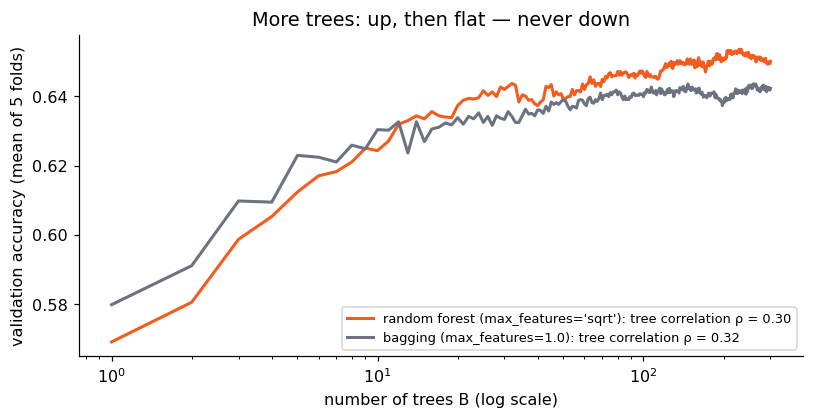

In [11]:
B_MAX = 300
curves = {}
for label, max_features in [("random forest (max_features='sqrt')", "sqrt"), ("bagging (max_features=1.0)", 1.0)]:
    rf_config = {"type": "random_forest",
                 "params": {"n_estimators": B_MAX, "max_features": max_features, "random_state": SEED, "n_jobs": -1}}
    per_fold, correlations = [], []
    for tr, va in cv.split(X_dev, y_dev):
        fitted = build_pipeline(PREP, rf_config).fit(X_dev.iloc[tr], y_dev.iloc[tr])
        Xv = fitted.named_steps["prep"].transform(X_dev.iloc[va])
        p = np.array([t.predict_proba(Xv)[:, 1] for t in fitted.named_steps["model"].estimators_])
        running = np.cumsum(p, axis=0) / np.arange(1, B_MAX + 1)[:, None]          # forest of the first B trees
        per_fold.append(((running >= 0.5) == y_dev.iloc[va].to_numpy()).mean(axis=1))
        c = np.corrcoef(p[:50]); correlations.append(c[np.triu_indices(50, 1)].mean())
    curves[label] = (np.mean(per_fold, axis=0), np.mean(correlations))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for (label, (curve, rho)), color in zip(curves.items(), [ORANGE, GRAY]):
    ax.plot(np.arange(1, B_MAX + 1), curve, color=color, lw=2, label=f"{label}: tree correlation ρ = {rho:.2f}")
    print(f"{label:<38s} 1 tree {curve[0]:.3f}   10 trees {curve[9]:.3f}   100 trees {curve[99]:.3f}   300 trees {curve[-1]:.3f}")
ax.set(xscale="log", xlabel="number of trees B (log scale)", ylabel=f"validation {scoring} (mean of 5 folds)",
       title="More trees: up, then flat — never down")
ax.legend(fontsize=8.5); plt.show()

- Both curves rise steeply over the first ~10 trees and then **flatten** - they never turn down. `n_estimators` is not an overfitting knob; it's a cost knob. That's why we **don't tune it**: we fix it (200 in the config) and spend the tuning budget on hyperparameters that change the answer.
- With random feature subsets, each tree is individually **weaker** (look at B = 1: it was denied the best feature at many splits) but the trees are **less correlated** (lower ρ). From about 20 trees on, the forest is ahead of plain bagging and stays ahead: decorrelation is worth more than individual strength.
- Both end well below the 0.67 of the tuned tree, though. These are **fully grown** trees, and Section 2.3 shows why that's a problem here.

<a class="anchor" id="rf-overfit"></a>
### 2.3 · Overfitting: does a forest want deep trees?

The textbook answer: averaging removes **variance**, not bias, so a forest should average **deep** (low-bias, high-variance) trees, and `max_depth=None` is the default. Does that hold here? The week 5 depth curve, for a single tree and for a forest, on the same folds:

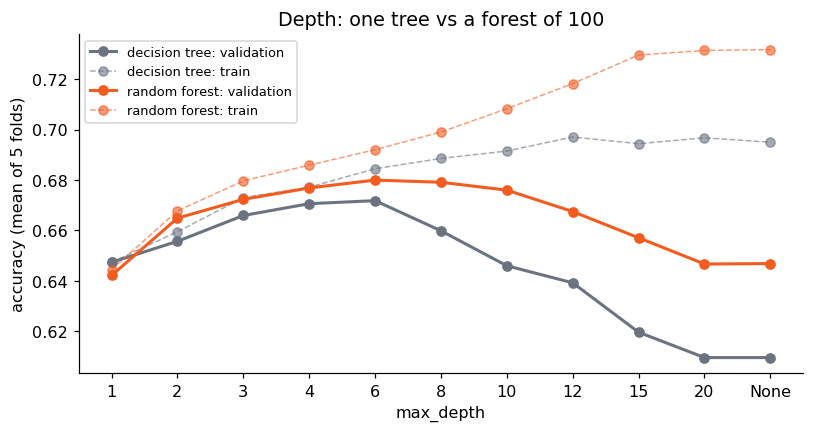

max_depth          1      2      3      4      6      8     10     12     15     20   None
model                                                                                     
decision tree  0.647  0.656  0.666  0.671  0.672  0.660  0.646  0.639  0.620  0.610  0.610
random forest  0.642  0.665  0.672  0.677  0.680  0.679  0.676  0.667  0.657  0.647  0.647


In [12]:
depths = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, None]
rows = []
for d in depths:
    for name, model_config in [
        ("decision tree", {"type": "decision_tree", "params": {"max_depth": d, "random_state": SEED}}),
        ("random forest", {"type": "random_forest", "params": {"n_estimators": 100, "max_depth": d,
                                                              "random_state": SEED, "n_jobs": -1}}),
    ]:
        fs, _ = cross_validate_pipeline(build_pipeline(PREP, model_config), X_dev, y_dev, cv, scoring)
        rows.append({"model": name, "max_depth": "None" if d is None else str(d),
                     "train": fs["train"].mean(), "validation": fs["validation"].mean()})
depth_curve = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.5, 4))
for name, color in [("decision tree", GRAY), ("random forest", ORANGE)]:
    c = depth_curve[depth_curve["model"] == name]
    ax.plot(c["max_depth"], c["validation"], "o-", color=color, lw=2, label=f"{name}: validation")
    ax.plot(c["max_depth"], c["train"], "o--", color=color, lw=1, alpha=0.6, label=f"{name}: train")
ax.set(xlabel="max_depth", ylabel=f"{scoring} (mean of 5 folds)", title="Depth: one tree vs a forest of 100")
ax.legend(fontsize=8.5); plt.show()
print(depth_curve.pivot(index="max_depth", columns="model", values="validation")
      .reindex([str(d) if d else "None" for d in depths]).round(3).T.to_string())

- The forest peaks **higher** than the tree (0.680 vs 0.672), and it stays near its peak over a much **wider** range of depths: averaging lets each tree be more complex before the whole thing overfits.
- Past the peak, the tree loses about twice as much as the forest (0.672 → 0.610 against 0.680 → 0.647). Averaging **halves** the damage of growing trees fully - it doesn't remove it.
- So on this data, `max_depth=None` is *not* the best forest. Why does the textbook advice fail here? Look back at the formula: averaging removes the variance of the part where the trees **disagree**. COMPAS has only 10 features after preprocessing, and many people share exactly the same feature values with different outcomes. A fully grown tree memorises those people's labels - and *every* tree in the forest memorises the same ones, because they all see most of the same rows. That memorised noise is **shared** (high ρ), so the average keeps it.

The cure for a forest isn't necessarily a depth cap. The other brake from week 5, `min_samples_leaf`, stops a leaf from being about one or two people while still letting the tree grow where there's enough data:

In [13]:
leaf_rows = []
for leaf in [1, 2, 5, 10, 20, 50, 100, 200]:
    rf_config = {"type": "random_forest", "params": {"n_estimators": 100, "min_samples_leaf": leaf,
                                                    "random_state": SEED, "n_jobs": -1}}
    fs, _ = cross_validate_pipeline(build_pipeline(PREP, rf_config), X_dev, y_dev, cv, scoring)
    leaf_rows.append({"min_samples_leaf": leaf, "train": fs["train"].mean(), "validation": fs["validation"].mean(),
                      "validation_std": fs["validation"].std(ddof=1), "gap": fs["gap"].mean()})
leaf_curve = pd.DataFrame(leaf_rows).set_index("min_samples_leaf")
print("random forest, fully grown (max_depth=None), 100 trees:")
print(leaf_curve.round(3).to_string())

random forest, fully grown (max_depth=None), 100 trees:
                  train  validation  validation_std    gap
min_samples_leaf                                          
1                 0.732       0.647           0.016  0.085
2                 0.717       0.659           0.014  0.058
5                 0.700       0.673           0.013  0.027
10                0.695       0.678           0.014  0.017
20                0.691       0.679           0.015  0.012
50                0.687       0.682           0.017  0.006
100               0.683       0.679           0.012  0.004
200               0.679       0.673           0.012  0.006


With leaves of a few dozen rows, a fully grown forest is as good as the best depth cap (or slightly better), and the train–validation gap almost closes. So the honest answer to *"deep or shallow?"* is: **a forest wants trees that are complex where the data supports it, and no more** - and only tuning can say where that is for a given dataset. Section 5 lets Optuna decide, with `max_depth`, `min_samples_leaf` and `max_features` together.

<a class="anchor" id="oob"></a>
### 2.4 · Out-of-bag score

From the theory class: every row is out-of-bag for about a third of the trees, so the forest can score each row using only the trees that never saw it - a validation score "for free", without CV. In scikit-learn it's `oob_score=True`:

In [14]:
oob_config = {"type": "random_forest", "params": {"n_estimators": 200, "min_samples_leaf": 20, "oob_score": True,
                                                 "random_state": SEED, "n_jobs": -1}}
oob_forest = build_pipeline(PREP, oob_config).fit(X_dev, y_dev)
fs, _ = cross_validate_pipeline(build_pipeline(PREP, oob_config), X_dev, y_dev, cv, scoring)
print(f"out-of-bag accuracy (one fit on all development rows): {oob_forest.named_steps['model'].oob_score_:.3f}")
print(f"5-fold CV accuracy (the pipeline's number):            {fs['validation'].mean():.3f} ± {fs['validation'].std(ddof=1):.3f}")

out-of-bag accuracy (one fit on all development rows): 0.677
5-fold CV accuracy (the pipeline's number):            0.682 ± 0.015


Close, from one fit instead of five. (Slightly lower: each row is judged by only the third of the trees that didn't see it, a smaller forest than the real one.) So why does the pipeline still use CV?

- **Only bagging models have out-of-bag rows.** Logistic regression and AdaBoost don't, and comparing models on *different* estimates isn't a fair comparison. CV works the same for every model, on the same folds.
- **Out-of-bag is out-of-bag for the trees only.** The preprocessing in front of the forest (imputer medians, scaler, encoder) was fitted on **all** development rows, out-of-bag ones included. Here that's nearly harmless — medians barely move, and the target encoder cross-fits - but any learned step in front of the model, such as feature selection, would leak the week 4 way. CV refits the whole pipeline in every fold.

Out-of-bag is a handy quick check while exploring a forest; CV is the number.

## <font color='#f35b1f'>3. Oblique Random Forest</font> <a class="anchor" id="oblique"></a>
[Back to TOC](#toc)

![ORF](https://developers.google.com/static/machine-learning/decision-forests/images/AxisAlignedvsOblique.png)

Every split we've seen so far asks about **one** feature: `priors_count <= 2.5`. Geometrically that's a line parallel to an axis, so a tree carves the feature space into rectangles. When the real boundary is diagonal- *"older people with more priors"*, a trade-off between two features - a tree needs a staircase of many small splits to follow it. An **oblique** split asks about a linear combination instead: $w_1x_1 + w_2x_2 + \dots \le c$, a slanted line.

<a class="anchor" id="oblique-split"></a>
### 3.1 · One oblique split, by hand

The idea of the theory class's CART-LC example on a small made-up dataset, where the classes are separated by a diagonal. The best split on one feature, against one split on $x_1 + x_2$:

In [15]:
rng = np.random.default_rng(1)
X2 = rng.uniform(0, 10, size=(300, 2))
y2 = (X2[:, 0] + X2[:, 1] + rng.normal(0, 0.3, 300) > 10).astype(int)      # a diagonal boundary, plus a little noise

def gini_gain(feature, y):
    stump = DecisionTreeClassifier(max_depth=1).fit(feature.reshape(-1, 1), y)
    t = stump.tree_
    root = t.impurity[0]
    children = (t.weighted_n_node_samples[1] * t.impurity[1] + t.weighted_n_node_samples[2] * t.impurity[2]) / t.weighted_n_node_samples[0]
    return t.threshold[0], root - children, stump.score(feature.reshape(-1, 1), y)

for label, feature in [("x1 alone", X2[:, 0]), ("x2 alone", X2[:, 1]), ("x1 + x2  (oblique)", X2[:, 0] + X2[:, 1])]:
    threshold, gain, acc = gini_gain(feature, y2)
    print(f"best split on {label:<20s} <= {threshold:5.2f}   Gini gain {gain:.3f}   accuracy {acc:.3f}")

best split on x1 alone             <=  6.22   Gini gain 0.143   accuracy 0.757
best split on x2 alone             <=  6.02   Gini gain 0.143   accuracy 0.760
best split on x1 + x2  (oblique)   <= 10.01   Gini gain 0.467   accuracy 0.983


One slanted split does what no single straight split can. The catch, from the theory class: there are infinitely many combinations $w$, so a real oblique tree can't try them all. CART-LC starts from the best axis-parallel split and **hill-climbs** the coefficients at every node. Random-forest-style oblique methods are lazier, and that's the point: they draw **random** sparse combinations and let the tree pick the best of them, exactly like a random forest draws random features.

<a class="anchor" id="oblique-build"></a>
### 3.2 · Building an oblique forest

scikit-learn has no oblique tree, but the random version can be built from two parts it does have:

1. **A random projection** turns the features into `n_components` random sparse linear combinations of them. Each new column is one candidate hyperplane direction.
2. **An ordinary decision tree** on those columns. Each of its splits, `combination <= c`, is a slanted split on the original features.

One oblique tree is a `Pipeline` of the two:

<div class="alert alert-block alert-info">
<a href='https://scikit-learn.org/stable/modules/generated/sklearn.random_projection.SparseRandomProjection.html'>sklearn.random_projection.SparseRandomProjection(n_components='auto', density='auto', random_state=None)</a>

**Definition:**
Multiplies the data by a random sparse matrix: every output column is a random combination of a few input columns, with weights ±w.

**Common Parameters:**
- `n_components`: how many combinations to create (here: candidate split directions per tree)
- `density`: share of non-zero weights; `'auto'` = 1/√(n_features), so each combination mixes about 3 of our 10 features
- `random_state`: which combinations are drawn
</div>

In [16]:
oblique_tree = Pipeline([
    ("project", SparseRandomProjection(n_components=10, random_state=0)),
    ("tree", DecisionTreeClassifier(max_features="sqrt", random_state=0)),
]).fit(Xp_train, yp_train)

W = oblique_tree.named_steps["project"].components_.toarray()        # one row per combination
short = [n.split("__")[1] for n in feature_names]
print("the first 3 combinations this tree can split on:")
for row in W[:3]:
    print("   " + "  ".join(f"{w:+.2f}*{f}" for w, f in zip(row, short) if w != 0))
root = oblique_tree.named_steps["tree"].tree_
print(f"\nits root split: combination {root.feature[0]} <= {root.threshold[0]:.2f}")

the first 3 combinations this tree can split on:
   +0.56*juv_misd_count  +0.56*priors_count  -0.56*priors_count_was_missing
   -0.56*juv_other_count  +0.56*c_charge_degree  -0.56*c_charge_degree_was_missing
   +0.56*juv_misd_count  +0.56*age_cat  +0.56*c_charge_degree

its root split: combination 6 <= 0.18


Note that the combinations mix features on very different scales unless they're scaled first - the theory's step 1 of CART-LC ("standardize the variables"). Our preprocessing already scales the numeric columns (robust scaler) and turns the categories into numbers (target encoding), so the combinations are meaningful.

**The forest** is the same recipe as a random forest - bootstrap samples, many trees, average - so it's scikit-learn's `BaggingClassifier` around the oblique tree. Bagging gives every copy its own `random_state`, so every tree gets its **own** random combinations:

<div class="alert alert-block alert-info">
<a href='https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html'>sklearn.ensemble.BaggingClassifier(estimator=None, n_estimators=10, max_samples=1.0, bootstrap=True, n_jobs=None, random_state=None)</a>

**Definition:**
Fits `n_estimators` copies of `estimator`, each on a bootstrap sample of the rows, and averages their predicted probabilities. A random forest is bagging of trees plus random features per split.

**Common Parameters:**
- `estimator`: the model to copy - any estimator, including a `Pipeline`
- `n_estimators`: number of copies
- `random_state`: seeds the bootstrap samples **and** every `random_state` inside each copy
</div>

<div class="alert alert-block alert-success">

🆕 <b>New this week → <code>src/model.py</code></b><br>
<code>oblique_random_forest()</code> - the two steps above, packaged: an oblique tree (projection → tree) inside <code>BaggingClassifier</code>. Its own arguments go to the forest and the projection; anything else (<code>min_samples_leaf</code>, <code>max_depth</code>…) goes to every tree.
</div>

In [17]:
# ---- src/model.py -- identical to the pipeline ----
def oblique_random_forest(n_estimators: int = 100, n_components: int = 10, density="auto",
                          random_state=None, n_jobs=None, **tree_params):
    """
    A forest of oblique trees: each tree is fit on a bootstrap sample, on `n_components`
    random sparse linear combinations of the features (a new set per tree), so its splits are
    hyperplanes. `tree_params` go to every tree (`max_features` defaults to "sqrt"). Tuned as
    `model__estimator__tree__<param>` and `model__estimator__project__<param>`.
    """
    tree_params.setdefault("max_features", "sqrt")
    oblique_tree = Pipeline([
        ("project", SparseRandomProjection(n_components=n_components, density=density)),
        ("tree", DecisionTreeClassifier(**tree_params)),
    ])
    return BaggingClassifier(estimator=oblique_tree, n_estimators=n_estimators,
                             random_state=random_state, n_jobs=n_jobs)

In [18]:
forest = oblique_random_forest(n_estimators=3, n_components=10, random_state=SEED).fit(Xp_train, yp_train)
for i, est in enumerate(forest.estimators_, 1):
    first = est.named_steps["project"].components_.toarray()[0]
    print(f"tree {i}: projection seed {est.named_steps['project'].random_state:>10d}   first combination: "
          + "  ".join(f"{w:+.2f}*{f}" for w, f in zip(first, short) if w != 0))

tree 1: projection seed 1952926171   first combination: +0.56*age
tree 2: projection seed 1761383086   first combination: -0.56*c_charge_degree  +0.56*priors_count_was_missing  +0.56*c_charge_degree_was_missing
tree 3: projection seed 1449071958   first combination: -0.56*c_charge_degree


<div class="alert alert-block alert-warning">

**The "real" oblique forest: `treeple`'s `ObliqueRandomForestClassifier`.** The oblique forest from the research literature is SPORF (*Sparse Projection Oblique Randomer Forests*, Tomita et al., 2020), and its reference implementation is the `ObliqueRandomForestClassifier` class in the `treeple` package (from the NeuroData lab, formerly called `scikit-tree`). It follows the scikit-learn interface (`fit`, `predict`, works inside a `Pipeline`), and works like this:

- at **every node**, it draws `max_features` new random sparse combinations of the features: each one mixes about `feature_combinations` features (default 1.5 on average), with weights +1 or −1;
- it finds the best threshold on each combination, and the node keeps the best combination + threshold;
- the rest is a random forest: bootstrap samples, many trees, average.

So the difference from ours is **where** the randomness is drawn: SPORF draws fresh combinations at every node, so each tree can use far more directions; ours draws one set per tree and every node chooses among them. (CART-LC, from the theory class, goes further still: it *optimises* the combination at every node instead of drawing it at random.)

**Why we don't use it:** `treeple` isn't part of scikit-learn: it ships its own copy of scikit-learn's tree code, which calls scikit-learn **private** functions (names starting with `_`, which can change in any release). Its last release (March 2025) hasn't caught up with scikit-learn 1.9, so `ObliqueRandomForestClassifier().fit(...)` fails with a `TypeError` from inside scikit-learn. It also has no ready-made install packages for the newest Python versions, so pip has to compile it from source there. Our version keeps the idea — random slanted splits, decorrelated by randomness, averaged - and runs anywhere scikit-learn runs. If `treeple` catches up, it could replace ours as one more entry in `_MODELS`.
</div>

<a class="anchor" id="oblique-picture"></a>
### 3.3 · Where it helps

The made-up diagonal data again: decision regions of one tree, a random forest and the oblique forest, with each one's 5-fold CV accuracy. Everything is built with the same functions, on the raw 2 features:

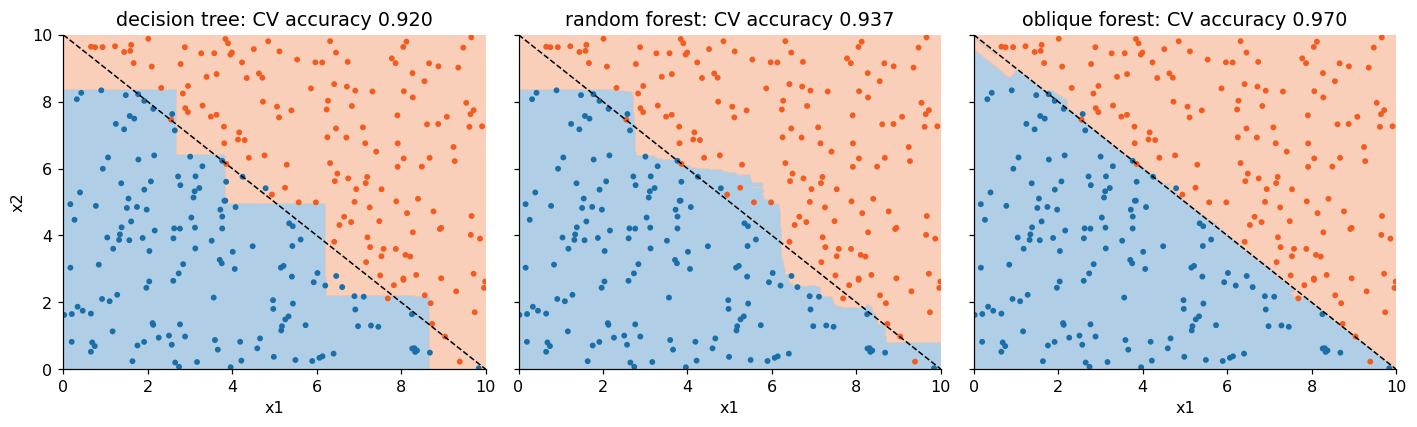

In [19]:
contenders = {
    "decision tree": DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED),
    "random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "oblique forest": oblique_random_forest(n_estimators=200, n_components=2, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
}
grid = np.stack(np.meshgrid(np.linspace(0, 10, 200), np.linspace(0, 10, 200)), axis=-1).reshape(-1, 2)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (name, model) in zip(axes, contenders.items()):
    acc = cross_val_score(model, X2, y2, cv=StratifiedKFold(5, shuffle=True, random_state=SEED)).mean()
    zz = model.fit(X2, y2).predict_proba(grid)[:, 1].reshape(200, 200)
    ax.contourf(np.linspace(0, 10, 200), np.linspace(0, 10, 200), zz, levels=[0, 0.5, 1], colors=[LIGHT, "#F9C4A9"], alpha=0.8)
    ax.scatter(X2[:, 0], X2[:, 1], c=np.where(y2 == 1, ORANGE, BLUE), s=8)
    ax.plot([0, 10], [10, 0], color="k", lw=1, ls="--")
    ax.set(title=f"{name}: CV accuracy {acc:.3f}", xlabel="x1")
axes[0].set_ylabel("x2"); plt.tight_layout(); plt.show()

The tree draws a staircase; the forest averages many staircases into a finer, but still blocky, edge; the oblique forest follows the diagonal - and it has the best CV score of the three. Oblique splits pay off when the classes are separated by **trade-offs between features**. Whether COMPAS is like that is an empirical question - Section 5 answers it, with the oblique forest tuned and compared on the same folds as everything else.

## <font color='#f35b1f'>4. AdaBoost</font> <a class="anchor" id="ada"></a>
[Back to TOC](#toc)

![ADA](https://media.geeksforgeeks.org/wp-content/uploads/20251114110952674323/420046939.webp)

A forest builds its trees **independently** and averages them. AdaBoost builds them **in sequence**: each new tree is trained on the same rows, but with **weights** that make it concentrate on the rows the ensemble has been getting wrong. Because every tree only has to fix part of the problem, they can be **weak** - usually stumps (depth-1 trees). Bagging reduces variance; boosting reduces **bias**.

<a class="anchor" id="ada-hand"></a>
### 4.1 · Three rounds by hand

The theory class's algorithm, on fold 1's preprocessed training rows (labels as $y \in \{-1, +1\}$):

1. every row starts with the same weight $1/n$;
2. fit a stump using the weights; its **total error** $\varepsilon$ is the sum of the weights of the rows it gets wrong;
3. its **amount of say** is $\alpha = \tfrac12 \ln\frac{1-\varepsilon}{\varepsilon}$;
4. multiply the weights of misclassified rows by $e^{\alpha}$ and of correct rows by $e^{-\alpha}$, then normalise to sum to 1;
5. repeat; the final prediction is the sign of $\sum_t \alpha_t h_t(x)$.

In [20]:
w = np.full(len(yp_train), 1 / len(yp_train))                 # 1. equal weights
signed = np.where(yp_train == 1, 1, -1)
hand_stumps, hand_says = [], []
for t in range(1, 4):
    stump = DecisionTreeClassifier(max_depth=1).fit(Xp_train, yp_train, sample_weight=w)    # 2. weighted stump
    wrong = stump.predict(Xp_train) != yp_train
    eps = w[wrong].sum()
    alpha = 0.5 * np.log((1 - eps) / eps)                                                   # 3. amount of say
    w = w * np.exp(np.where(wrong, alpha, -alpha)); w = w / w.sum()                         # 4. re-weight
    hand_stumps.append(stump); hand_says.append(alpha)
    s = stump.tree_
    print(f"round {t}: stump splits on {short[s.feature[0]]:<26s} <= {s.threshold[0]:6.2f}   "
          f"error ε = {eps:.3f}   say α = {alpha:.3f}   weight now on the misclassified rows: {w[wrong].sum():.2f}")

F_val = sum(a * np.where(s.predict(Xp_val) == 1, 1, -1) for a, s in zip(hand_says, hand_stumps))      # 5. weighted vote
print(f"\n3-stump ensemble, validation accuracy {((F_val > 0).astype(int) == yp_val).mean():.3f}")

round 1: stump splits on priors_count               <=   0.12   error ε = 0.352   say α = 0.306   weight now on the misclassified rows: 0.50
round 2: stump splits on age                        <=   0.09   error ε = 0.407   say α = 0.189   weight now on the misclassified rows: 0.50
round 3: stump splits on priors_count               <=   1.38   error ε = 0.445   say α = 0.110   weight now on the misclassified rows: 0.50

3-stump ensemble, validation accuracy 0.644


Three things to see:

- **After every round, the misclassified rows carry exactly half of the weight** (the 0.50 printed). On the new weights, the stump just added would be no better than a coin flip, so the next stump is forced to find a different split: `age` in round 2, and `priors_count` again in round 3 but at a different threshold.
- **Say follows error.** The stumps' errors grow as the easy structure is used up, so later stumps get less say.
- The exponential loss behind it (theory class) is also AdaBoost's weak spot: a row that keeps being misclassified - for example, one with a **wrong label** - gets exponentially more weight, and later trees bend over backwards to fit it.

The same three rounds with scikit-learn's `AdaBoostClassifier`:

<div class="alert alert-block alert-info">
<a href='https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html'>sklearn.ensemble.AdaBoostClassifier(estimator=None, n_estimators=50, learning_rate=1.0, random_state=None)</a>

**Definition:**
Fits `n_estimators` copies of `estimator` in sequence, re-weighting the training rows after each one (the SAMME algorithm), and predicts by a weighted vote.

**Common Parameters:**
- `estimator`: the weak learner - default a stump, `DecisionTreeClassifier(max_depth=1)`
- `n_estimators`: the number of rounds. Unlike a forest's trees, **more rounds can overfit** (Section 4.3)
- `learning_rate`: multiplies every learner's say; smaller = smaller steps, so more rounds are needed
- `random_state`: seeds the learners
</div>

In [21]:
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=3, random_state=SEED).fit(Xp_train, yp_train)
for t, (stump, hand, alpha) in enumerate(zip(ada.estimators_, hand_stumps, hand_says), 1):
    same = (stump.tree_.feature[0] == hand.tree_.feature[0]) and np.isclose(stump.tree_.threshold[0], hand.tree_.threshold[0])
    print(f"round {t}: same stump as ours? {same}   sklearn's say {ada.estimator_weights_[t - 1]:.3f} = 2 x {alpha:.3f}")
print(f"validation accuracy {ada.score(Xp_val, yp_val):.3f}")

round 1: same stump as ours? True   sklearn's say 0.611 = 2 x 0.306
round 2: same stump as ours? True   sklearn's say 0.378 = 2 x 0.189
round 3: same stump as ours? True   sklearn's say 0.220 = 2 x 0.110
validation accuracy 0.644


The same stumps. scikit-learn's say is exactly **twice** ours: it uses $\ln\frac{1-\varepsilon}{\varepsilon}$ without the ½. Every say is doubled, so every vote total is doubled, so every prediction is the same. (The weight updates are identical too: it multiplies only the misclassified rows by $e^{2\alpha}$, which after normalising is the same as our $e^{\alpha}$ / $e^{-\alpha}$.) `learning_rate` multiplies that say; with the default 1.0 this is the algorithm from the theory class.

<div class="alert alert-block alert-success">

🆕 <b>New this week → <code>src/model.py</code></b><br>
<code>adaboost()</code> - <code>AdaBoostClassifier</code> with a decision tree of depth <code>max_depth</code> as the weak learner (1 = stumps). A function rather than the class itself, because the base tree is an object and <code>config.yaml</code> can only hold plain values. The base tree's depth is then tuned through the nested name <code>model__estimator__max_depth</code>.
</div>

In [22]:
# ---- src/model.py -- identical to the pipeline ----
def adaboost(max_depth: int = 1, **params):
    """
    AdaBoost over decision trees of depth `max_depth` (1 = stumps); `params` go to
    AdaBoostClassifier. The trees' depth is tuned as `model__estimator__max_depth`.
    """
    return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=max_depth), **params)

<a class="anchor" id="registry"></a>
### 4.2 · Registering the new models

<div class="alert alert-block alert-success">

🆕 <b>New this week → <code>src/model.py</code></b><br>
<code>_MODELS</code> - the two builders join the registry, so <code>model.type</code> in <code>config.yaml</code> can now be <code>"oblique_random_forest"</code> or <code>"adaboost"</code>. <code>build_model()</code> doesn't change: it calls <code>_MODELS[type](**params)</code>, and a function works there exactly like a class.
</div>

In [23]:
# ---- src/model.py -- identical to the pipeline (replaces the version from Section 1.3) ----
_MODELS = {
    "dummy": DummyClassifier,
    "logistic_regression": LogisticRegression,
    "decision_tree": DecisionTreeClassifier,
    "random_forest": RandomForestClassifier,
    "oblique_random_forest": oblique_random_forest,
    "adaboost": adaboost,
}

In [24]:
for model_config in [{"type": "adaboost", "params": {"max_depth": 2, "n_estimators": 100, "random_state": SEED}},
                     {"type": "oblique_random_forest", "params": {"n_estimators": 200, "random_state": SEED}}]:
    print(build_pipeline(PREP, model_config).named_steps["model"], "\n")

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2),
                   n_estimators=100, random_state=42) 

BaggingClassifier(estimator=Pipeline(steps=[('project',
                                             SparseRandomProjection(n_components=10)),
                                            ('tree',
                                             DecisionTreeClassifier(max_features='sqrt'))]),
                  n_estimators=200, random_state=42) 



<a class="anchor" id="ada-overfit"></a>
### 4.3 · Overfitting: weak learners, and the learning rate

AdaBoost overfits in two ways a forest doesn't: through **too strong** base trees, and through **too many rounds**. One fit per fold of 300 rounds is enough to see both - `staged_predict()` gives the ensemble's prediction after every round. Base trees of depth 1, 3 and 8, each with `learning_rate` 1.0 and 0.1:

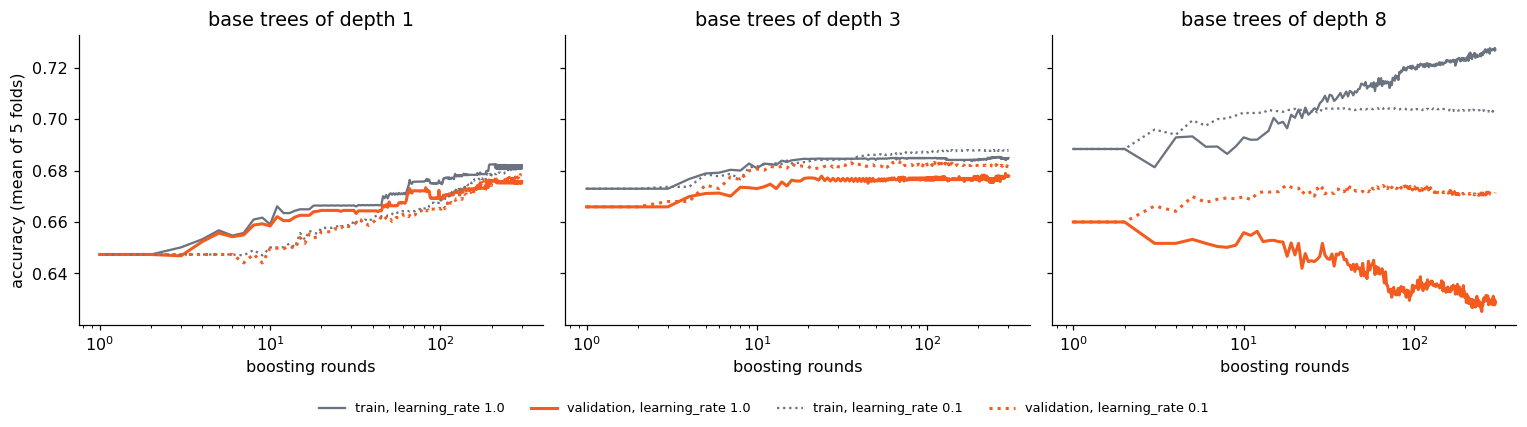

 base depth  learning_rate  best validation  at round  validation after 300  train after 300
          1            1.0            0.676       192                 0.676            0.682
          1            0.1            0.679       288                 0.678            0.681
          3            1.0            0.679       288                 0.678            0.685
          3            0.1            0.684       120                 0.682            0.688
          8            1.0            0.660         1                 0.629            0.727
          8            0.1            0.674        18                 0.671            0.703


In [25]:
ROUNDS = 300
staged = {}
for depth in [1, 3, 8]:
    for lr in [1.0, 0.1]:
        ada_config = {"type": "adaboost", "params": {"max_depth": depth, "n_estimators": ROUNDS, "learning_rate": lr,
                                                     "random_state": SEED}}
        tr_curves, va_curves = [], []
        for tr, va in cv.split(X_dev, y_dev):
            fitted = build_pipeline(PREP, ada_config).fit(X_dev.iloc[tr], y_dev.iloc[tr])
            booster, prep_fold = fitted.named_steps["model"], fitted.named_steps["prep"]
            for idx, store in [(tr, tr_curves), (va, va_curves)]:
                Xs, ys = prep_fold.transform(X_dev.iloc[idx]), y_dev.iloc[idx].to_numpy()
                store.append([(p == ys).mean() for p in booster.staged_predict(Xs)])
        staged[(depth, lr)] = (np.mean(tr_curves, axis=0), np.mean(va_curves, axis=0))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
rounds = np.arange(1, ROUNDS + 1)
for ax, depth in zip(axes, [1, 3, 8]):
    for lr, style in [(1.0, "-"), (0.1, ":")]:
        tr_c, va_c = staged[(depth, lr)]
        ax.plot(rounds, tr_c, style, color=GRAY, lw=1.5, label=f"train, learning_rate {lr}")
        ax.plot(rounds, va_c, style, color=ORANGE, lw=2, label=f"validation, learning_rate {lr}")
    ax.set(title=f"base trees of depth {depth}", xlabel="boosting rounds", xscale="log")
axes[0].set_ylabel(f"{scoring} (mean of 5 folds)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8.5, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

summary = pd.DataFrame([{"base depth": d, "learning_rate": lr, "best validation": va.max(), "at round": va.argmax() + 1,
                         "validation after 300": va[-1], "train after 300": tr[-1]}
                        for (d, lr), (tr, va) in staged.items()])
print(summary.round(3).to_string(index=False))

- **Stumps (depth 1)** can't overfit much: train and validation stay together, and validation keeps creeping up for hundreds of rounds. Each stump is a high-bias learner, and boosting reduces that bias, slowly. With `learning_rate=0.1` it is slower still - it hasn't finished after 300 rounds.
- **Depth 3** starts higher (one depth-3 tree already beats a stump) and levels off within a few dozen rounds. Depth 3 with `learning_rate=0.1` is the best of the six settings.
- **Depth 8 at `learning_rate=1.0`** is the overfitting picture: train climbs with every round, validation is best at round **1** and then **falls**. A deep tree fits the training rows almost perfectly, so the rows it still gets wrong are mostly noise, and the next trees concentrate on exactly those. A strong learner leaves boosting nothing to do but memorise.
- **A smaller `learning_rate`** shrinks every tree's say, so each round changes the ensemble less: curves move to the right (more rounds needed) and get smoother, and even depth 8 is held back. `learning_rate` and `n_estimators` trade off against each other, which is why they're tuned **together**.

So the pattern is the **opposite** of the forest's: AdaBoost wants **weak** base trees, and its number of rounds *is* an overfitting knob. Both go in its search space.

## <font color='#f35b1f'>5. Tuning the Ensembles</font> <a class="anchor" id="tuning"></a>
[Back to TOC](#toc)

<a class="anchor" id="spaces"></a>
### 5.1 · The search spaces

**Changed this week:** the `tuning` section of `config.yaml`, with one search space per ensemble. The tuning code itself (`tune_pipeline()`, `nested_cross_validate()`) doesn't change at all: it reads whatever space belongs to `model.type`.

In [26]:
# ---- config.yaml -- CHANGED this week: the tuning section ----
config.update(yaml.safe_load("""
tuning:
  enabled: true
  n_trials: 30
  n_splits: 5                                       # folds that score each candidate
  random_state: 42                                  # seeds the sampler and those folds
  # Keys are Pipeline parameter names. Types: int / float (low, high, log) or categorical (choices).
  # Ensembles take minutes per run: use a small n_trials while testing.
  search_spaces:
    decision_tree:
      model__max_depth: {type: int, low: 1, high: 20}
      model__min_samples_leaf: {type: int, low: 1, high: 200, log: true}
      model__criterion: {type: categorical, choices: ["gini", "entropy"]}
    random_forest:
      model__max_depth: {type: int, low: 2, high: 30}
      model__min_samples_leaf: {type: int, low: 1, high: 200, log: true}
      model__max_features: {type: categorical, choices: ["sqrt", 0.5, 1.0]}
    oblique_random_forest:
      model__estimator__tree__max_depth: {type: int, low: 2, high: 30}
      model__estimator__tree__min_samples_leaf: {type: int, low: 1, high: 200, log: true}
      model__estimator__project__n_components: {type: int, low: 3, high: 10}   # <= number of features
    adaboost:
      model__estimator__max_depth: {type: int, low: 1, high: 8}
      model__n_estimators: {type: int, low: 25, high: 400, log: true}
      model__learning_rate: {type: float, low: 0.01, high: 1.0, log: true}
"""))
tuning_config = config["tuning"]
print(list(tuning_config["search_spaces"]))

['decision_tree', 'random_forest', 'oblique_random_forest', 'adaboost']


Each space follows from what Sections 2–4 showed about the model:

| Model | Tuned | Not tuned (fixed in `params`) | Why |
|---|---|---|---|
| random forest | `max_depth`, `min_samples_leaf` (tree size), `max_features` (decorrelation; `1.0` = bagging) | `n_estimators: 200` | more trees never overfit (2.2); tree size does (2.3) |
| oblique forest | the same tree size, through `model__estimator__tree__…`; `n_components` (how many directions each tree may use) | `n_estimators: 200` | same logic; at most 10 directions = no more than the number of features |
| AdaBoost | the base tree's depth (`model__estimator__max_depth`), `n_estimators`, `learning_rate` | — | depth controls how weak the learners are; rounds and learning rate trade off (4.3) |

The names follow the `Pipeline` path, step by step: `model__estimator__tree__max_depth` is the `max_depth` of the step `tree`, inside the `estimator` of the step `model`. `set_params()` accepts any such path:

In [27]:
p = build_pipeline(PREP, {"type": "oblique_random_forest", "params": {"random_state": SEED}})
p.set_params(model__estimator__tree__min_samples_leaf=20, model__estimator__project__n_components=6)
print(p.named_steps["model"].estimator)

Pipeline(steps=[('project', SparseRandomProjection(n_components=6)),
                ('tree',
                 DecisionTreeClassifier(max_features='sqrt',
                                        min_samples_leaf=20))])


<a class="anchor" id="results"></a>
### 5.2 · Default vs tuned, honestly

First every model with its **default** `params` from the config, the first table `python main.py` prints:

In [28]:
MODEL_CONFIGS = {
    "random_forest": {"type": "random_forest", "params": {"n_estimators": 200, "random_state": SEED, "n_jobs": -1}},
    "oblique_random_forest": {"type": "oblique_random_forest",
                              "params": {"n_estimators": 200, "n_components": 10, "random_state": SEED, "n_jobs": -1}},
    "adaboost": {"type": "adaboost", "params": {"max_depth": 1, "n_estimators": 200, "learning_rate": 1.0,
                                                "random_state": SEED}},
}
assert MODEL_CONFIGS["random_forest"] == config["model"]          # the model main.py runs

default_scores = {}
for name, model_config in MODEL_CONFIGS.items():
    t0 = time.time()
    default_scores[name], _ = cross_validate_pipeline(build_pipeline(PREP, model_config), X_dev, y_dev, cv, scoring)
    fs = default_scores[name]
    print(f"{name:<22s} default: validation {fs['validation'].mean():.3f} ± {fs['validation'].std(ddof=1):.3f}"
          f"   gap {fs['gap'].mean():+.3f}   ({time.time() - t0:.0f}s)")

random_forest          default: validation 0.650 ± 0.019   gap +0.082   (3s)
oblique_random_forest  default: validation 0.647 ± 0.011   gap +0.114   (5s)
adaboost               default: validation 0.676 ± 0.012   gap +0.006   (4s)


Then the tuned versions, with **nested CV**: exactly the week 5 call in `main.py`, once per model (30 trials, 5 inner folds, the same 5 outer folds as above). The decision tree is included, so this week's table and last week's line up. This is the slow part, so it's pre-run: with `RUN_NESTED = False` the tables are loaded from `prerun/`, where this same cell saved them.

In [29]:
RUN_NESTED = False                     # True: recompute (tens of minutes); False: load the pre-run tables
PRERUN_DIR = Path("prerun")

search_spaces = tuning_config["search_spaces"]
n_trials, tuning_seed = tuning_config["n_trials"], tuning_config["random_state"]
inner_cv = StratifiedKFold(n_splits=tuning_config["n_splits"], shuffle=True, random_state=tuning_seed)

nested = {}
for name, model_config in {"decision_tree": DT, **MODEL_CONFIGS}.items():
    path = PRERUN_DIR / f"nested_{name}.csv"
    if RUN_NESTED:
        t0 = time.time()
        nested[name], _ = nested_cross_validate(build_pipeline(PREP, model_config), X_dev, y_dev, cv, inner_cv, scoring,
                                                search_spaces[name], n_trials, tuning_seed)
        PRERUN_DIR.mkdir(exist_ok=True); nested[name].to_csv(path, index=False)
        print(f"{name}: {time.time() - t0:.0f}s")
    else:
        nested[name] = pd.read_csv(path)

,default: CV,default: gap,tuned: nested CV,tuned: gap
model,,,,
logistic regression,0.672 ± 0.013,+0.003,—,—
decision tree,0.610 ± 0.018,+0.085,0.672 ± 0.017,+0.013
random forest,0.650 ± 0.019,+0.082,0.681 ± 0.015,+0.009
oblique random forest,0.647 ± 0.011,+0.114,0.679 ± 0.013,+0.013
adaboost,0.676 ± 0.012,+0.006,0.682 ± 0.017,+0.004


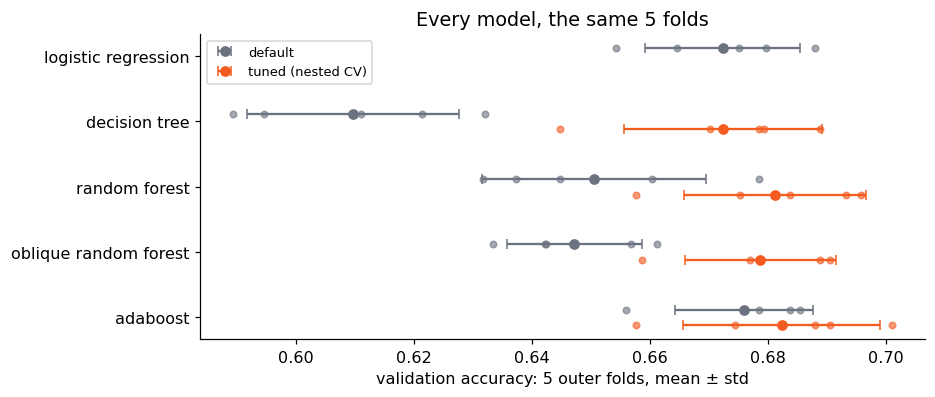

In [30]:
rows = [{"model": "logistic regression", "default": baseline["Logistic regression"]["validation"],
         "default gap": baseline["Logistic regression"]["gap"], "tuned": None, "tuned gap": None},
        {"model": "decision tree", "default": baseline["Decision tree (defaults)"]["validation"],
         "default gap": baseline["Decision tree (defaults)"]["gap"],
         "tuned": nested["decision_tree"]["validation"], "tuned gap": nested["decision_tree"]["gap"]}]
for name in MODEL_CONFIGS:
    rows.append({"model": name.replace("_", " "), "default": default_scores[name]["validation"],
                 "default gap": default_scores[name]["gap"], "tuned": nested[name]["validation"], "tuned gap": nested[name]["gap"]})

fmt = lambda s: "—" if s is None else f"{s.mean():.3f} ± {s.std(ddof=1):.3f}"
table = pd.DataFrame([{"model": r["model"],
                       "default: CV": fmt(r["default"]), "default: gap": f"{r['default gap'].mean():+.3f}",
                       "tuned: nested CV": fmt(r["tuned"]),
                       "tuned: gap": "—" if r["tuned gap"] is None else f"{r['tuned gap'].mean():+.3f}"} for r in rows])
display(table.set_index("model"))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
for i, r in enumerate(rows):
    ax.scatter(r["default"], [i - 0.12] * 5, color=GRAY, s=18, alpha=0.6)
    ax.errorbar(r["default"].mean(), i - 0.12, xerr=r["default"].std(ddof=1), fmt="o", color=GRAY, capsize=3,
                label="default" if i == 0 else None)
    if r["tuned"] is not None:
        ax.scatter(r["tuned"], [i + 0.12] * 5, color=ORANGE, s=18, alpha=0.6)
        ax.errorbar(r["tuned"].mean(), i + 0.12, xerr=r["tuned"].std(ddof=1), fmt="o", color=ORANGE, capsize=3,
                    label="tuned (nested CV)" if i == 1 else None)
ax.set_yticks(range(len(rows)), [r["model"] for r in rows]); ax.invert_yaxis()
ax.set(xlabel=f"validation {scoring}: 5 outer folds, mean ± std", title="Every model, the same 5 folds")
ax.legend(fontsize=8.5, loc="upper left"); plt.show()

Since all rows use the **same five folds**, the differences can also be read fold by fold, the paired comparison from weeks 4-5:

In [31]:
paired = pd.DataFrame({name.replace("_", " "): nested[name]["validation"].to_numpy() for name in ["decision_tree", *MODEL_CONFIGS]},
                      index=pd.Index(range(1, 6), name="outer fold"))
paired["logistic regression"] = baseline["Logistic regression"]["validation"].to_numpy()
best = paired.mean().idxmax()
display(paired.round(3))
print(f"best mean: {best}.  Its fold-by-fold difference against each of the others:")
print((paired[[best]].to_numpy() - paired.drop(columns=best)).agg(["mean", "std", "min", "max"]).round(3).to_string())

,decision tree,random forest,oblique random forest,adaboost,logistic regression
outer fold,,,,,
1,0.670,0.675,0.677,0.674,0.680
2,0.645,0.658,0.659,0.658,0.654
3,0.679,0.693,0.691,0.701,0.675
4,0.689,0.684,0.689,0.688,0.688
5,0.679,0.696,0.679,0.691,0.665


best mean: adaboost.  Its fold-by-fold difference against each of the others:
      decision tree  random forest  oblique random forest  logistic regression
mean          0.010          0.001                  0.004                0.010
std           0.009          0.005                  0.007                0.015
min          -0.001         -0.005                 -0.003               -0.005
max           0.023          0.008                  0.012                0.026


What the table and the fold-by-fold differences say:

- **Tuning mattered most where the defaults overfit.** Both forests grow their trees fully by default (gaps of +0.08 and +0.11), and tuning lifts them by about three points, to 0.68. AdaBoost with stumps was already well-behaved by default (gap +0.006); tuning adds a little.
- **Tuned, the three ensembles are tied.** AdaBoost has the best mean, but against the random forest it's +0.001 on average, with folds going both ways. Picking the "winner" among them would be picking noise.
- **Against last week's models, the ensembles gain about one point** (+0.010). Against the tuned tree that holds in 4 of 5 folds; against logistic regression the folds go both ways (from −0.006 to +0.026). Whether +0.01 is real is exactly what week 5's corrected paired t-test decides (Challenge 8).
- **The oblique forest doesn't beat the ordinary one here.** COMPAS's features are counts and encoded categories, and the signal is mostly "more priors, younger": something one-feature splits express well. Compare Section 3.3, where the boundary really was diagonal.
- **Everything ends near 0.68.** Five very different models hitting the same ceiling says the limit is the **information in these 10 features**, not the model. More model won't help much; better features might (Section 6).

## <font color='#f35b1f'>6. Challenge Warm-up: Engineering a Feature for the Trees</font> <a class="anchor" id="fe"></a>
[Back to TOC](#toc)

A tree can only ask *"is this one column above a threshold?"*. Some relationships are awkward to express that way. A **rate** is the classic example: *2 priors at 19* and *2 priors at 45* are very different histories, but splits on `priors_count` and `age` separately need a whole staircase to approximate "priors per year of adulthood" - and even an oblique split can only combine features linearly, not divide them. If we think a ratio matters, we can hand it to the model directly.

This is a fixed formula - nothing is learned from the data - so, like `add_missingness_indicators()`, it can be computed **before the split**, and it's equally safe on new data. (A feature that needs a statistic, such as *"priors above the median"*, would have to be a step inside the `Pipeline` instead, so the median comes from training rows only.)

<div class="alert alert-block alert-warning">

**Example - not in the pipeline.** `add_engineered_features()` is the worked example for Challenge 1. If you add it to your pipeline, it belongs in `src/preprocessing.py`, called before `split_features_target()` in `main.py`, and the new column must be listed in `preprocessing.numeric_features`.
</div>

In [33]:
def add_engineered_features(df: pd.DataFrame) -> pd.DataFrame:
    # EXAMPLE (Challenge 1). Fixed formulas only -- nothing is learned, so this is safe before the split.
    out = df.copy()
    out["priors_per_adult_year"] = out["priors_count"] / (out["age"] - 17).clip(lower=1)   # NaN stays NaN -> imputed later
    return out


df_eng = add_engineered_features(df_clean)
X_eng, _, _ = split_features_target(df_eng, config["data"], config["preprocessing"]["mnar_indicator_sources"])
X_dev_eng = X_eng.loc[X_dev.index]                    # the SAME development rows -> the same folds as everywhere else
PREP_ENG = copy.deepcopy(PREP)
PREP_ENG["numeric_features"] = PREP["numeric_features"] + ["priors_per_adult_year"]

RF_FE = {"type": "random_forest", "params": {"n_estimators": 200, "min_samples_leaf": 20, "random_state": SEED, "n_jobs": -1}}
fe = {}
for label, model_config in [("logistic regression", LR), ("random forest (leaf 20)", RF_FE)]:
    before, _ = cross_validate_pipeline(build_pipeline(PREP, model_config), X_dev, y_dev, cv, scoring)
    after, _ = cross_validate_pipeline(build_pipeline(PREP_ENG, model_config), X_dev_eng, y_dev, cv, scoring)
    fe[label] = after["validation"].to_numpy() - before["validation"].to_numpy()
    print(f"{label:<25s} without {before['validation'].mean():.3f}   with {after['validation'].mean():.3f}   "
          f"difference per fold {np.round(fe[label], 3)}")

logistic regression       without 0.672   with 0.675   difference per fold [ 0.003  0.004  0.003 -0.002  0.003]
random forest (leaf 20)   without 0.682   with 0.681   difference per fold [ 0.004  0.003 -0.001 -0.007 -0.001]


Logistic regression gains a little in 4 of the 5 folds: consistent, but small next to the fold-to-fold spread. The forest gains **nothing**: the folds go both ways, around zero. With leaves of 20+ people, splits on `age` and `priors_count` together already approximate the rate well enough, while logistic regression — which can't combine two features into a rate on its own — can only use it if we provide it.

So a feature can help one model family and not another: **measure, don't assume**. And this is with fixed hyperparameters. For a tuned model, the fair comparison re-tunes with the new features and compares **nested** scores, as Challenge 1 asks.

## <font color='#f35b1f'>7. Adding the Ensembles to Your Pipeline</font> <a class="anchor" id="pipeline"></a>
[Back to TOC](#toc)

**No Step 0 this week:** no new packages, so no `pip install`. Everything is in scikit-learn, which you already have.

The functions in green boxes are copied verbatim into `src/model.py`; the two changed config cells (`model`, `tuning`) are exactly what goes into `config.yaml`:

| File | Change |
|---|---|
| `src/model.py` | new imports (`AdaBoostClassifier`, `BaggingClassifier`, `SparseRandomProjection`); new `adaboost()` and `oblique_random_forest()` (Sections 3.2, 4.1); `_MODELS` with the two new entries (Section 4.2) |
| `config.yaml` | `model`: the random forest, with the other models as commented examples; `tuning.search_spaces`: `random_forest`, `oblique_random_forest`, `adaboost` (Section 5.1) |

Nothing else changes - `main.py`, `src/tuning.py` and the reports all work through `build_pipeline()` and the config. To run a model, set `model.type` (and its `params`) and run `python main.py`, as before.

**It takes longer.** An ensemble is 100–300 trees, so one run with tuning on takes minutes instead of seconds: roughly 5–15 minutes per model on a recent laptop (`(cv.n_splits + 1) × n_trials × tuning.n_splits` = 900 fits). While you're building and testing, set `tuning.n_trials: 5` or `tuning.enabled: false`; do the full run once, at the end, for your README.

**Check yourself:** with `model.type: "adaboost"` and `tuning.enabled: true`, which config entries decide the base trees' depth during nested CV, and which decide it in the final model? (During tuning, the search space overrides `params.max_depth` in every trial; the final model uses the best trial's value.)

# <font color='#f35b1f'>Key Takeaways</font> <a class="anchor" id="takeaways"></a>
[Back to TOC](#toc)

## Update your README (due Saturday 23:59)

Add this week's row to "Pipeline progress", and extend "Model evaluation" with a table for every model so far. Get each row from `python main.py` with that `model.type` (tuning on); keep the full runs for the end, and use a small `n_trials` while testing.

```markdown
### Ensembles
| Model | Default: CV mean ± std (gap) | Tuned: nested CV mean ± std (gap) | Tuning score (best trial) | Chosen hyperparameters |
|---|---|---|---|---|
| Logistic regression | ... | — | — | — |
| Decision tree | ... | ... | ... | ... |
| Random forest | ... | ... | ... | ... |
| Oblique random forest | ... | ... | ... | ... |
| AdaBoost | ... | ... | ... | ... |

3–5 sentences: which model would you choose, and is its lead bigger than the fold-to-fold std?
Do the chosen hyperparameters match how each model works (deep or shallow trees, and why)?
Which model and which number would you report?
```

## Challenges

Start with 1. The rest are for going further. Keep the rules for every change: development set only, whole pipeline, same folds, nested CV for anything tuned.

1. **Feature engineering in your pipeline.** Add `add_engineered_features()` (Section 6) to `src/preprocessing.py`, call it before `split_features_target()` in `main.py`, and list the new column in `preprocessing.numeric_features`. Then invent **at least two** features of your own: ratios, sums, interactions, bins with fixed edges. Does each one need anything learned from the data? If it does, it can't go before the split. Compare **nested** scores with and without your features for the random forest, AdaBoost and logistic regression. Which model family gains, and by more than the fold std?
2. **Boost something that isn't a tree.** Try `AdaBoostClassifier(estimator=LogisticRegression(max_iter=2000))`. Does boosting improve a linear model? What does a weighted sum of linear models give you? (Hint: is it still linear?)
